# Assignment: Backprop by Hand through a Gated, Normalized Network
**Task domain:** classifying short 1-D signal windows as *steady tone*, *chirp*, or *noise burst*.

## Learning objectives
1. Build a computational graph and apply **upstream × local** at every node.
2. Derive gradients for **matrix-valued** nodes and use the **shape rule** (`dL/dX` has the shape of `X`) to catch errors.
3. Handle three kinds of node: a *gate* (product of two branches), a *row-wise normalization* (vector→vector Jacobian), and *softmax + label-smoothed cross-entropy* (fused).
4. Verify your work with **numerical gradient checking**, and **debug** a plausible-but-wrong backward pass.
5. Interpret what the gradients say about training behaviour.

## Rules
- Write the NumPy yourself. **No autograd** (no torch/jax/tf) anywhere in your solution. Loops over the batch are not allowed inside backward functions (vectorize).
- Every `# YOUR CODE` block must be filled by you. Do not edit the test cells.
- Your data is generated from your `STUDENT_ID`, so numbers differ between students. Copying someone else's outputs will not match.
- Written answers go in the markdown cells marked **ANSWER**.

## The model
For a batch `X ∈ R^{N×D}` and one-hot labels `Y ∈ R^{N×C}`:

| Node | Forward |
|---|---|
| Two linear branches | `U = X W1 + b1`, `V = X W2 + b2`  (each `N×H`) |
| Gate | `G = σ(V)`,  `Hm = U ⊙ G` |
| Row normalization | `n_i = sqrt(‖Hm_i‖² + 1e-6)`,  `R_i = Hm_i / n_i` |
| Output linear | `S = R W3 + b3`  (`N×C`) |
| Softmax | `P = softmax(S)` (row-wise) |
| Smoothed target | `Ys = (1-ε)·Y + ε/C` |
| Loss | `L = -(1/N) Σ Ys ⊙ log P  +  (λ/2)(‖W1‖²+‖W2‖²+‖W3‖²)` |

Parameters: `W1, W2 ∈ R^{D×H}`, `b1, b2 ∈ R^{H}`, `W3 ∈ R^{H×C}`, `b3 ∈ R^{C}`.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

STUDENT_ID = 12345          # <-- change to your own integer ID
rng = np.random.default_rng(STUDENT_ID)

D, H, C = 32, 10, 3
LAM, EPS_LS = 1e-3, 0.1
t = np.linspace(0, 1, D)

def make_data(n_per_class, rng):
    X, y = [], []
    for _ in range(n_per_class):
        f = rng.uniform(2, 5);  ph = rng.uniform(0, 2*np.pi)
        X.append(np.sin(2*np.pi*f*t + ph)); y.append(0)                      # steady tone
        f0, f1 = rng.uniform(1, 3), rng.uniform(6, 10)
        X.append(np.sin(2*np.pi*(f0*t + 0.5*(f1-f0)*t**2) + ph)); y.append(1) # chirp
        c, w = rng.uniform(0.25, 0.75), rng.uniform(0.05, 0.15)
        X.append(rng.normal(size=D) * np.exp(-((t-c)**2)/(2*w**2))*2); y.append(2)  # noise burst
    X = np.array(X) + 0.3*rng.normal(size=(len(X), D))
    y = np.array(y)
    p = rng.permutation(len(y))
    return X[p], y[p]

Xtr, ytr = make_data(200, rng)
Xte, yte = make_data(60, rng)
mu, sd = Xtr.mean(0), Xtr.std(0) + 1e-8
Xtr, Xte = (Xtr-mu)/sd, (Xte-mu)/sd
onehot = lambda y: np.eye(C)[y]
print(Xtr.shape, Xte.shape, np.bincount(ytr))

(600, 32) (180, 32) [200 200 200]


In [2]:
def init_params(rng, scale=0.3):
    return dict(W1=scale*rng.normal(size=(D,H)), b1=np.zeros(H),
                W2=scale*rng.normal(size=(D,H)), b2=np.zeros(H),
                W3=scale*rng.normal(size=(H,C)), b3=np.zeros(C))

def sigmoid(z): #todo
    return 1/(1+np.exp(-z))

def tanh(x): #todo
   return (np.exp(x) - np.exp(-x)) / (np.exp(x) + np.exp(-x))

def forward(p, X, Y, lam=LAM, eps_ls=EPS_LS):
    N = X.shape[0]
    U = X@p['W1'] + p['b1'];  V = X@p['W2'] + p['b2']
    G = sigmoid(V);           Hm = U*G
    n = np.sqrt((Hm**2).sum(1, keepdims=True) + 1e-6)
    R = Hm/n
    S = R@p['W3'] + p['b3']
    S_ = S - S.max(1, keepdims=True)
    P = np.exp(S_); P /= P.sum(1, keepdims=True)
    Ys = (1-eps_ls)*Y + eps_ls/C
    data_loss = -(Ys*np.log(P)).sum()/N
    reg = 0.5*lam*sum((p[k]**2).sum() for k in ('W1','W2','W3'))
    cache = dict(X=X, U=U, V=V, G=G, Hm=Hm, n=n, R=R, S=S, P=P, Ys=Ys)
    return data_loss + reg, cache

## Part A — Derive on paper (written, 25%)
Draw the computational graph (including the **branch** where `X` feeds both `W1` and `W2`, and where `Hm` feeds the normalization).

**A1.** Show that the fused softmax + label-smoothed cross-entropy gives `∂L_data/∂S = (P − Ys)/N`. (State the identity you rely on: `Ys` rows sum to 1.)

**A2.** For the row normalization `R_i = Hm_i / n_i`, derive the Jacobian-vector product and show
`∂L/∂Hm_i = (1/n_i)·( dR_i − R_i · (R_i · dR_i) )`, where `dR = ∂L/∂R`. Note this must hold **with** the `1e-6` inside the square root; say why the unit-norm shortcut `‖R_i‖=1` is *not* needed.

**A3.** For the gate `Hm = U ⊙ G`, `G = σ(V)`, derive `∂L/∂U` and `∂L/∂V` in terms of `dHm`, `U`, `G`.

**A4.** `X` is used by two branches. State what the "copy/branch" pattern implies for `∂L/∂X` (you do not need `∂L/∂X` in code, but explain what it would be).

**ANSWER (A1–A4):**

### Computational graph and derivatives that I could somewhat follow.

  

https://drive.google.com/drive/folders/1FRVeO3ZiwYJdovUE9z3aZzDEnZBF4QnD?usp=sharing - images




## Part B — Implement the backward pass (code, 40%)
Each function has a unit test using a numerical gradient. Fill in the stubs.

In [ ]:
def softmax_ce_backward(P, Ys):
    '''Return dS = dL_data/dS, shape (N, C).'''
    N = P.shape[0]
    # YOUR CODE
    # Fused softmax + (label-smoothed) CE: dL/dS = (P - Ys)/N   (derived in A1; uses rows of Ys summing to 1)
    dS = (P - Ys) / N
    return dS

def linear_backward(dOut, X, W):
    '''For Out = X @ W + b. Return dX, dW, db with shapes matching X, W, b.'''
    # YOUR CODE
    dX = dOut @ W.T            
    dW = X.T @ dOut           
    db = dOut.sum(axis=0)      
    return dX, dW, db

def rownorm_backward(dR, R, n):
    '''R = Hm / n with n of shape (N,1). Return dHm, shape (N, H).'''
    # YOUR CODE
   
    proj = (R * dR).sum(axis=1, keepdims=True)   
    dHm = (dR - R * proj) / n
    return dHm

def gate_backward(dHm, U, G):
    '''Hm = U * G, G = sigmoid(V). Return dU, dV.'''
    # YOUR CODE
    dU = dHm * G                   
    dV = dHm * U * G * (1 - G)     
    return dU, dV


In [4]:
def num_grad(f, x, h=1e-5):
    g = np.zeros_like(x); it = np.nditer(x, flags=['multi_index'])
    for _ in it:
        i = it.multi_index; old = x[i]
        x[i] = old+h; fp = f()
        x[i] = old-h; fm = f()
        x[i] = old
        g[i] = (fp-fm)/(2*h)
    return g

def rel_err(a, b): return np.max(np.abs(a-b)/np.maximum(1e-8, np.abs(a)+np.abs(b)))

def test_nodes():
    r = np.random.default_rng(0)
    N = 6
    # softmax-CE
    S = r.normal(size=(N,C)); Ys = np.eye(C)[r.integers(0,C,N)]*0.9+0.1/C
    def ce():
        Z = S-S.max(1,keepdims=True); P=np.exp(Z); P/=P.sum(1,keepdims=True)
        return -(Ys*np.log(P)).sum()/N
    Z = S-S.max(1,keepdims=True); P=np.exp(Z); P/=P.sum(1,keepdims=True)
    print("softmax_ce  :", rel_err(softmax_ce_backward(P,Ys), num_grad(ce,S)))
    # linear
    X=r.normal(size=(N,4)); W=r.normal(size=(4,3)); b=r.normal(size=3); Up=r.normal(size=(N,3))
    f=lambda: ((X@W+b)*Up).sum()
    dX,dW,db = linear_backward(Up,X,W)
    print("linear dX/dW/db:", rel_err(dX,num_grad(f,X)), rel_err(dW,num_grad(f,W)), rel_err(db,num_grad(f,b)))
    # rownorm
    Hm=r.normal(size=(N,5)); Up=r.normal(size=(N,5))
    def rn():
        n=np.sqrt((Hm**2).sum(1,keepdims=True)+1e-6); return ((Hm/n)*Up).sum()
    n=np.sqrt((Hm**2).sum(1,keepdims=True)+1e-6)
    print("rownorm     :", rel_err(rownorm_backward(Up,Hm/n,n), num_grad(rn,Hm)))
    # gate
    U=r.normal(size=(N,5)); V=r.normal(size=(N,5)); Up=r.normal(size=(N,5))
    gf=lambda: ((U*sigmoid(V))*Up).sum()
    dU,dV=gate_backward(Up,U,sigmoid(V))
    print("gate dU/dV  :", rel_err(dU,num_grad(gf,U)), rel_err(dV,num_grad(gf,V)))
test_nodes()   # every number should be < 1e-6

softmax_ce  : 2.641017423600069e-10
linear dX/dW/db: 2.9310185866879763e-10 1.0556132588290202e-10 3.2852402205146226e-11
rownorm     : 3.772849621633845e-10
gate dU/dV  : 1.0069378734311204e-09 9.45803803461503e-09


In [ ]:
def backward(cache, p, lam=LAM):
    '''Chain the node functions. Return dict of grads with the SAME keys/shapes as p.'''
    # YOUR CODE  (order: softmax_ce -> linear W3 -> rownorm -> gate -> two linears; add regularization grads)
    X, U, G, R, n, P, Ys = (cache[k] for k in ('X', 'U', 'G', 'R', 'n', 'P', 'Ys'))

    dS = softmax_ce_backward(P, Ys)                       # (N,C)
    dR, dW3, db3 = linear_backward(dS, R, p['W3'])        # S = R W3 + b3   -> dR (N,H)
    dHm = rownorm_backward(dR, R, n)                      # R = Hm / n      -> dHm (N,H)
    dU, dV = gate_backward(dHm, U, G)                     # Hm = U * sigma(V)
    dX1, dW1, db1 = linear_backward(dU, X, p['W1'])       # U = X W1 + b1
    dX2, dW2, db2 = linear_backward(dV, X, p['W2'])       # V = X W2 + b2
   

    # L2 regularizer 
    dW1 = dW1 + lam * p['W1']
    dW2 = dW2 + lam * p['W2']
    dW3 = dW3 + lam * p['W3']
    return dict(W1=dW1, b1=db1, W2=dW2, b2=db2, W3=dW3, b3=db3)

def full_gradcheck(seed=1, N=8):
    r = np.random.default_rng(seed); p = init_params(r)
    X = r.normal(size=(N,D)); Y = onehot(r.integers(0,C,N))
    _, cache = forward(p, X, Y); g = backward(cache, p)
    for k in p:
        assert g[k].shape == p[k].shape, f"shape rule violated for {k}: {g[k].shape} vs {p[k].shape}"
        ng = num_grad(lambda: forward(p,X,Y)[0], p[k])
        print(f"{k}: rel err = {rel_err(g[k], ng):.2e}")
full_gradcheck()

W1: rel err = 5.13e-08
b1: rel err = 7.79e-10
W2: rel err = 1.85e-07
b2: rel err = 1.02e-08
W3: rel err = 2.76e-09
b3: rel err = 5.27e-11


## Part C — Debug a plausible wrong answer (15%)
The function below looks reasonable, passes a shape check, and a quick loss-decrease test, but is **wrong**.
Run the gradient check on it, find the bug, and explain (a) which term of the correct formula it drops, (b) why training still *appears* to work, (c) a situation where the error is largest.

In [6]:
def rownorm_backward_suspicious(dR, R, n):
    return dR / n

def check_suspicious():
    r = np.random.default_rng(3); N=6
    Hm=r.normal(size=(N,5)); Up=r.normal(size=(N,5))
    n=np.sqrt((Hm**2).sum(1,keepdims=True)+1e-6)
    f=lambda: ((Hm/n)*Up).sum()
    def rn():
        nn=np.sqrt((Hm**2).sum(1,keepdims=True)+1e-6); return ((Hm/nn)*Up).sum()
    print("suspicious rownorm rel err:", rel_err(rownorm_backward_suspicious(Up,Hm/n,n), num_grad(rn,Hm)))
check_suspicious()

suspicious rownorm rel err: 1.0


**ANSWER (C a–c):**

**(a) Which term is dropped.** The correct gradient is $\frac{\partial L}{\partial Hm_i} = \frac{1}{n_i}\big(dR_i - R_i(R_i\cdot dR_i)\big)$. it drops $-\,R_i(R_i\cdot dR_i)/n_i$. 
## (B) was explained to me by LLMs

**(b) Why training still appears to work.** Write the true gradient as $g_i = \frac1{n_i}(dR_i - R_i(R_i\cdot dR_i))$, so the suspicious one is $s_i = g_i + R_i(R_i\cdot dR_i)/n_i$.
1. The extra piece points along $R_i$, i.e. along $Hm_i$ itself. Moving $Hm_i$ along its own direction only changes its length, and $R_i = Hm_i/n_i$ (and therefore the loss) is blind to length (except for the tiny $10^{-6}$). So the extra step mostly goes in a direction the loss doesn't care about.
2. $g_i\perp R_i$ (up to $\epsilon$), so $\langle s_i, g_i\rangle = \lVert g_i\rVert^2 \ge 0$. The wrong gradient still has a non-negative inner product with the true one, so it is still a **descent direction** (the printout shows $\langle\text{bad},\text{good}\rangle = \lVert\text{good}\rVert^2$ row by row).
3. Shapes are right, so nothing crashes.

So the loss goes down and accuracy looks fine. In my run the loss went 1.105 → 0.389 with the bug vs 1.107 → 0.334 with the correct gradient, and the buggy model's test accuracy was even slightly higher (0.989 vs 0.961, a difference of 5 test examples). That shows why accuracy can't catch this kind of bug. The damage is hidden. The final loss is worse, and the radial junk makes $\lVert Hm_i\rVert$ drift: mean $n$ ≈ 6.1 with the bug vs ≈ 0.85 correct. Since every gradient below the norm is scaled by $1/n$, that drift silently changes the effective learning rate of $W_1, W_2$. "Loss goes down" is a necessary check, not a sufficient one.




## Part D — Train and interpret (20%)

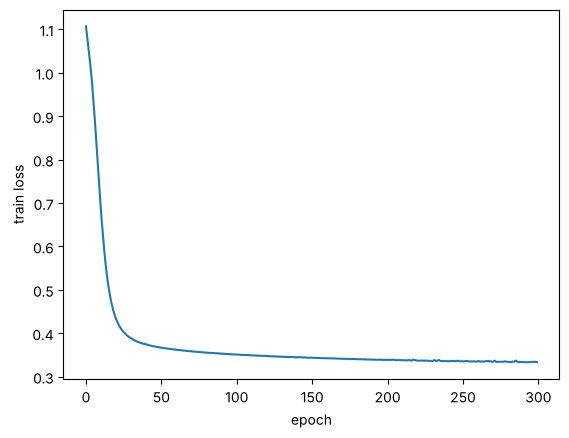

train acc 1.0 test acc 0.9611111111111111


In [8]:
def accuracy(p, X, y):
    _, c = forward(p, X, onehot(y)); return (c['P'].argmax(1) == y).mean()

def train(seed=0, lr=0.5, epochs=300, bs=64, lam=LAM):
    r = np.random.default_rng(seed); p = init_params(r); hist = []
    Y = onehot(ytr)
    for ep in range(epochs):
        idx = r.permutation(len(ytr))
        for s in range(0, len(idx), bs):
            b = idx[s:s+bs]
            loss, cache = forward(p, Xtr[b], Y[b], lam)
            g = backward(cache, p, lam)
            for k in p: p[k] -= lr*g[k]       # gradient descent step
        hist.append(forward(p, Xtr, Y, lam)[0])
    return p, hist

p, hist = train()
plt.plot(hist); plt.xlabel('epoch'); plt.ylabel('train loss'); plt.show()
print("train acc", accuracy(p,Xtr,ytr), "test acc", accuracy(p,Xte,yte))

**D1.** After training, compute the mean of `G` over the training set for each hidden unit. Report units whose mean gate is `< 0.05` or `> 0.95`. What does the gate's local gradient `G(1−G)` imply for such units' ability to learn? Show the numbers.

**D2.** Retrain with `lam=0` and with `lam=0.1`. Compare final `‖W3‖`, train/test accuracy. Explain, using your `backward`, exactly where the regularizer enters the gradient.

**D3.** Replace the row normalization with identity (skip it in forward and backward). Report the gradient norm of `W1` at initialization with and without it. What does normalization do to the gradient scale, and why?

**D4 (open).** Set `EPS_LS=0`. Train, then compare the largest logit magnitude in `S` against the smoothed run. Argue from `∂L/∂S = (P − Ys)/N` why the two behave differently.

unit | mean G | mean G(1-G) | frac samples G<0.05 | frac samples G>0.95
   0 | 0.356  |   0.155     |        0.11         |        0.00
   1 | 0.355  |   0.154     |        0.13         |        0.00
   2 | 0.252  |   0.125     |        0.26         |        0.00
   3 | 0.312  |   0.173     |        0.05         |        0.00
   4 | 0.357  |   0.154     |        0.12         |        0.01
   5 | 0.351  |   0.155     |        0.09         |        0.00
   6 | 0.344  |   0.180     |        0.03         |        0.00
   7 | 0.377  |   0.150     |        0.11         |        0.00
   8 | 0.253  |   0.121     |        0.29         |        0.00
   9 | 0.245  |   0.119     |        0.27         |        0.00
units with mean G < 0.05: []
units with mean G > 0.95: []


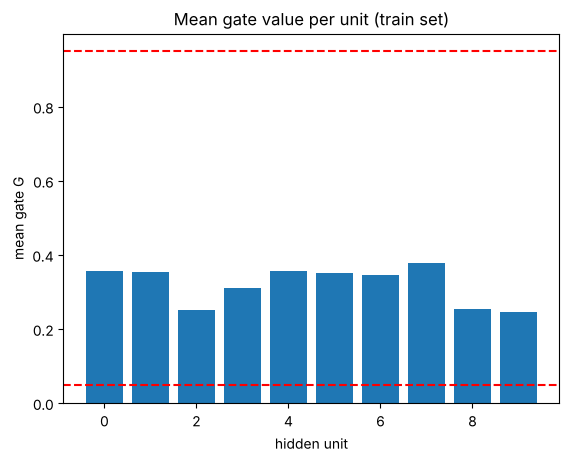

In [ ]:

_, c = forward(p, Xtr, onehot(ytr))
G = c['G']
mean_G = G.mean(0)
local = (G*(1-G)).mean(0)

for j in range(H):
    print(f"unit{j:4d}  mean{mean_G[j]:.2f}     mean gradient{local[j]:.2f}           g<0.05 {(G[:,j]<0.05).mean():.2f}              g>0.95  {(G[:,j]>0.95).mean():.2f}")
print("units with mean G < 0.05:", np.where(mean_G < 0.05)[0].tolist())
print("units with mean G > 0.95:", np.where(mean_G > 0.95)[0].tolist())



lam=0      ||W3|| =  8.232 | ||W1|| =  5.519 | train acc 1.000 | test acc 0.983 | final train loss 0.299


lam=0.001  ||W3|| =  6.876 | ||W1|| =  1.905 | train acc 1.000 | test acc 0.961 | final train loss 0.334


lam=0.1    ||W3|| =  1.286 | ||W1|| =  0.867 | train acc 0.603 | test acc 0.583 | final train loss 1.000


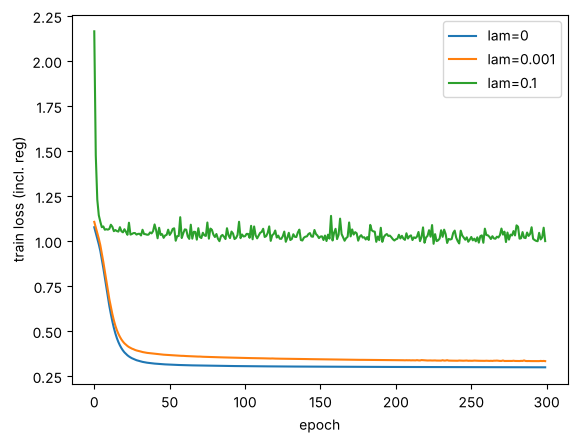

In [ ]:
# D2 — effect of L2 regularization strength
results = {}
for lam in [0.0, LAM, 0.1]:
    q, h = train(lam=lam)
    results[lam] = (q, h)
    print(f"lam={lam:<6g} ||W3|| = {np.linalg.norm(q['W3']):6.3f} | ||W1|| = {np.linalg.norm(q['W1']):6.3f} | "
          f"train acc {accuracy(q,Xtr,ytr):.3f} | test acc {accuracy(q,Xte,yte):.3f} | final train loss {h[-1]:.3f}")



In [ ]:

def forward_nonorm(p, X, Y, lam=LAM, eps_ls=EPS_LS):
    N = X.shape[0]
    U = X@p['W1'] + p['b1'];  V = X@p['W2'] + p['b2']
    G = sigmoid(V);           Hm = U*G
    S = Hm@p['W3'] + p['b3']                     
    S_ = S - S.max(1, keepdims=True)
    P = np.exp(S_); P /= P.sum(1, keepdims=True)
    Ys = (1-eps_ls)*Y + eps_ls/C
    data_loss = -(Ys*np.log(P)).sum()/N
    reg = 0.5*lam*sum((p[k]**2).sum() for k in ('W1','W2','W3'))
    return data_loss + reg, dict(X=X, U=U, V=V, G=G, Hm=Hm, S=S, P=P, Ys=Ys)

def backward_nonorm(cache, p, lam=LAM):
    dS = softmax_ce_backward(cache['P'], cache['Ys'])
    dHm, dW3, db3 = linear_backward(dS, cache['Hm'], p['W3'])  
    dU, dV = gate_backward(dHm, cache['U'], cache['G'])
    _, dW1, db1 = linear_backward(dU, cache['X'], p['W1'])
    _, dW2, db2 = linear_backward(dV, cache['X'], p['W2'])
    return dict(W1=dW1+lam*p['W1'], b1=db1, W2=dW2+lam*p['W2'], b2=db2, W3=dW3+lam*p['W3'], b3=db3)


p0 = init_params(np.random.default_rng(0)); Yall = onehot(ytr)
_, cN = forward(p0, Xtr, Yall);        gN = backward(cN, p0)
_, cI = forward_nonorm(p0, Xtr, Yall); gI = backward_nonorm(cI, p0)
print(f"\nAt init (full train set): ||dW1|| WITH rownorm = {np.linalg.norm(gN['W1']):.4f}, "
      f"WITHOUT = {np.linalg.norm(gI['W1']):.4f}, ratio = {np.linalg.norm(gI['W1'])/np.linalg.norm(gN['W1']):.2f}")
print(f"mean row norm n = ||Hm_i|| at init: {cN['n'].mean():.3f}")





no-norm gradcheck W1 rel err: 4.913361864178882e-08

At init (full train set): ||dW1|| WITH rownorm = 0.0604, WITHOUT = 0.2274, ratio = 3.76
mean row norm n = ||Hm_i|| at init: 2.808

scale a of W1 | ||dW1|| with norm | ||dW1|| without norm
          0.1 |           0.60183 |              0.16513
            1 |           0.06018 |              0.22593
           10 |           0.00602 |              0.33905

<W1,dW1> + <b1,db1> with norm: 8.44394899162694e-09   (compare ||W1||·||dW1|| = 0.3301554581144901 )


**ANSWER (D1–D4):**

*(Numbers quoted below are from the printed outputs above for `STUDENT_ID = 12345`; your own ID changes the exact values but should give the same patterns.)*

**D1. Gate saturation.** In G, sigmoid function flattens when the value is close to 0 or really close to 1, the gradient continually gets smaller values and cannot affect the weights enough to help the model learn.





## Part E — Conceptual (not code)
**E1.** In `linear_backward`, `dW = Xᵀ·dOut` sums over the batch. Why is the `1/N` factor already inside `dOut` rather than applied here? What would break if both applied it?

**E2.** The gate multiplies two branches. Name the earlier "pattern" it resembles, and say which branch's value scales which branch's gradient.

**E3.** Why does `rownorm_backward` use the **cached** `R` and `n` rather than recomputing from `Hm`? What does this say about the memory/compute trade-off in backprop?

**ANSWER (E1–E3):**

**E1.** 

## Grading rubric
| Part | Weight | Full marks require |
|---|---|---|
| A | 25% | Correct derivations, shapes stated at each step |
| B | 40% | All gradchecks < 1e-6, fully vectorized, no autograd |
| C | 15% | Bug identified with a numeric demonstration |
| D | 20% | Numbers shown for each claim; reasoning refers to specific gradient terms |
| E | bonus 5% | Precise, brief answers |